# 03 · detsim

**Purpose.** Raw waveforms after detsim, fibers and PMTs on the same nexus events.

**Inputs.** `<sample>_<i>.detsim.h5`, made from the slim nexus files of `tools/slim_nexus.py` (new runs, see below) (new: `$ICA_OUT/...`; 2025: `$OLD_IC_DIR/detsim`, PMTs in `detsim/PMTs`).

**Outputs.** None.

**What is checked.** stored detsim config of every file; S1 and S2 integrals per event for fibers and PMTs on the same events; the S1 placeholder (60 PMT waveforms copied into 108 fiber channels).

**Next step.** `04_hypathia`. Run with `./submit.sh detsim <fibers|pmts> <sample>`.

In [6]:
# Setup: run `source env.sh` before starting Jupyter, or pick the IC-3.8-2024-06-08 kernel.
import os, sys, glob
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from icana import paths, checks, fits
print("ICDIR =", paths.ICDIR or "NOT SET (source env.sh)")

ICDIR = /scratch/marian/IC_ANALYSIS/external/IC/invisible_cities


### Slim nexus inputs and reading in chunks (why the new detsim runs need them)

**What happened.** The first gain-1050 run on the 50Kev Kr sample (jobs 8043384–8043420, 2026-11-18) was killed by the memory limit (12 GB) at the very end of each detsim task, after all 50 000 events had been simulated.

**Why.** Every IC city used here (detsim, hypathia, dorothea) ends by copying the MC tables of its input into its output: `components.copy_mc_info` → `mcinfo_io.read_mc_tables`, which loads each table **whole** into pandas before keeping the events of the file. In these EL-off Kr files `/MC/particles` has 93 million rows (608 bytes each, 56.5 GB per file). About 99.7 % of them are `ie-`, the ionization electrons that nexus tracked one by one (about 1850 per Kr event); the real particles (`e-`, `gamma`) are about 5 per event. The 2025 jobs got through because they asked for 200 GB – 2 TB per task.

**What changes.** `tools/slim_nexus.py` (job `slurm/slim_nexus.slurm`, one file per task) writes a copy of each nexus file with the `ie-` rows of `/MC/particles` removed. Everything else is copied unchanged: `/MC/hits` (the energy deposits detsim uses to make the signal), `sns_response`, `sns_positions`, `configuration`. It reads `/MC/particles` **in chunks of 10⁶ rows** (about 0.6 GB at a time), so the job itself needs only ~2 GB, and it writes `<file>.part`, renamed only after the checks pass: same row count in every other table, and every event with hits still has its particles.

**What it does not change.** Detsim, hypathia and dorothea never read `/MC/particles` (they only copy it), and no notebook of this repository reads it, so the waveforms, PMAPs and Kr resolution are the same as with the full file. The `ie-` information is still in the original files in `$NEXUS_DIR`, which are not touched.

**Then, one step at a time.** detsim reads the slim files → its outputs are copied to `/data` from the login node (`tools/store.sh`; compute nodes cannot write `/data`) → hypathia → copy → dorothea. Each step needs only a couple of GB.

**Reading the events in chunks (fibers).** A full 50 000-event file took ~19 h of fiber detsim in 2025 at gain 365, and longer at gain 1050, so it would pass the 1-day job limit. Each file is therefore split with IC's `event_range` into chunks of events, one task per chunk, each writing its own `<sample>_<i>_<chunk>.detsim.h5`. The chunks of one file together contain exactly the events of the file; the cell below the next one checks it. *(Chunking: to be added to `submit.sh` before the fiber run.)*

The next cell compares one slim file with its original.

In [7]:
# Slim vs original nexus file: what was removed, and that nothing else changed.
# Reads only the first 10^6 rows of the original /MC/particles (the whole table is 56 GB).
import tables as tb
SUB, SAMPLE_SLIM, I_SLIM = "Kr", "20250626_Next100_50Kev_ELoff_Kr", 1
orig = f"{paths.NEXUS_DIR}/{SUB}/{SAMPLE_SLIM}_{I_SLIM}.next.h5"
slim = f"{paths.ICA_OUT}/nexus_slim/{SUB}/{SAMPLE_SLIM}_{I_SLIM}.next.h5"
with tb.open_file(orig) as fo, tb.open_file(slim) as fs:
    print(f"size: {os.path.getsize(orig)/1e9:.1f} GB -> {os.path.getsize(slim)/1e9:.2f} GB")
    for node in fo.walk_nodes("/", "Leaf"):
        print(f"  {node._v_pathname:20s} {node.nrows:>12,d} -> {fs.get_node(node._v_pathname).nrows:>12,d} rows")
    head = fo.root.MC.particles.read(0, 1_000_000)
    names, counts = np.unique(head["particle_name"], return_counts=True)
    print("particle names, first 10^6 rows of the original:", {n.decode(): int(c) for n, c in zip(names, counts)})
    ps = fs.root.MC.particles.read()
    print("particle names in the slim file:", {n.decode(): int(c) for n, c in zip(*np.unique(ps["particle_name"], return_counts=True))})
    ev_hits = np.unique(fs.root.MC.hits.col("event_id"))
    print(f"events with hits: {len(ev_hits):,d}; of them without particles in the slim file: {len(np.setdiff1d(ev_hits, np.unique(ps['event_id'])))}")
    # same hits, row by row, for the first 10^5 rows
    print("first 10^5 hits identical:", np.array_equal(fo.root.MC.hits.read(0, 100_000), fs.root.MC.hits.read(0, 100_000)))

size: 57.1 GB -> 0.05 GB
  /MC/configuration              41 ->           41 rows
  /MC/hits                3,171,925 ->    3,171,925 rows
  /MC/particles          92,973,997 ->      253,099 rows
  /MC/sns_positions           3,486 ->        3,486 rows
  /MC/sns_response        1,194,134 ->    1,194,134 rows
particle names, first 10^6 rows of the original: {'e-': 2564, 'gamma': 149, 'ie-': 997287}
particle names in the slim file: {'e-': 239066, 'gamma': 14033}
events with hits: 50,000; of them without particles in the slim file: 0
first 10^5 hits identical: True


In [8]:
EL_GAIN = paths.EL_GAIN   # gain of the new runs to read (folder <det>_g<EL_GAIN>)
SAMPLE, I = "20250624_Next100_1Kev_ELoff_Kr", 1     # file index; the 1Kev sample exists for both detectors
USE_NEW = False                                       # True: files made by this repository
def detsim_file(det):
    fs = paths.new_files(SAMPLE, det, "detsim", EL_GAIN) if USE_NEW else paths.old_files(SAMPLE, det, "detsim")
    return [f for f in fs if paths.file_index(f.replace("_PMTs", "")) == I][0]
f_fib, f_pmt = detsim_file("fibers"), detsim_file("pmts"); print(f_fib); print(f_pmt)
checks.summary_ic([f_fib, f_pmt])

/data/marian/IC/detsim/20250624_Next100_1Kev_ELoff_Kr_1.detsim.h5
/data/marian/IC/detsim/PMTs/20250624_Next100_1Kev_ELoff_Kr_1_PMTs.detsim.h5


,file,readable,error,detector_db,s1_table,s2_table,el_gain,lifetime_ms,nexus_input
0,20250624_Next100_1Kev_ELoff_Kr_1.detsim.h5,True,,next100fibers,NEXT100_S1_LT.h5,/scratch/marian/s2simulation/outputs/20250408_...,365,12.0,20250624_Next100_1Kev_ELoff_Kr_1.next.h5
1,20250624_Next100_1Kev_ELoff_Kr_1_PMTs.detsim.h5,True,,next100,NEXT100_S1_LT.h5,$ICDIR/database/test_data/NEXT100_S2_LT.h5,365,12.0,20250624_Next100_1Kev_ELoff_Kr_1.next.h5


### Plots (2025 style)
Same plots as the 2025 notebook `python_cluster/notebooks/20250428_s2simulation_ICdetsim.ipynb`, now as functions in `icana/plots.py`.
They use the files chosen above (`SAMPLE`, `I`, `USE_NEW`). `EVENTS` are row numbers in the file (0, 1, 2, ...); the title shows the nexus event number.
With `SAVE = True` every figure is also written to `work/figures/` as PDF (for the thesis) and PNG.

1. **Hits** of one event: what detsim starts from (`/MC/hits`, copied from the nexus file), relative to the event centre.
2. **Waveforms** of the energy plane (fibers or PMTs, 100 ns bins) and of the SiPMs (1 µs bins): *sum* of all channels, *average* per channel, and the *highest* channel. S1 is at 100 µs, S2 comes after the drift time.
3. **Fibers vs PMTs** on the same event (same nexus file, same row).
4. The same, **zoomed on S2**.

In [9]:
from icana import plots
plots.set_style()
EVENTS = [0, 1, 2]     # rows to show (2025 notebook: 10 events)
SAVE   = False         # True: also save each figure to work/figures/
tag    = f"{SAMPLE}_{I}_{'new' if USE_NEW else '2025'}"
def show(fig, name):
    if SAVE: print("saved", plots.save(fig, f"{tag}_{name}"))
    plt.show()

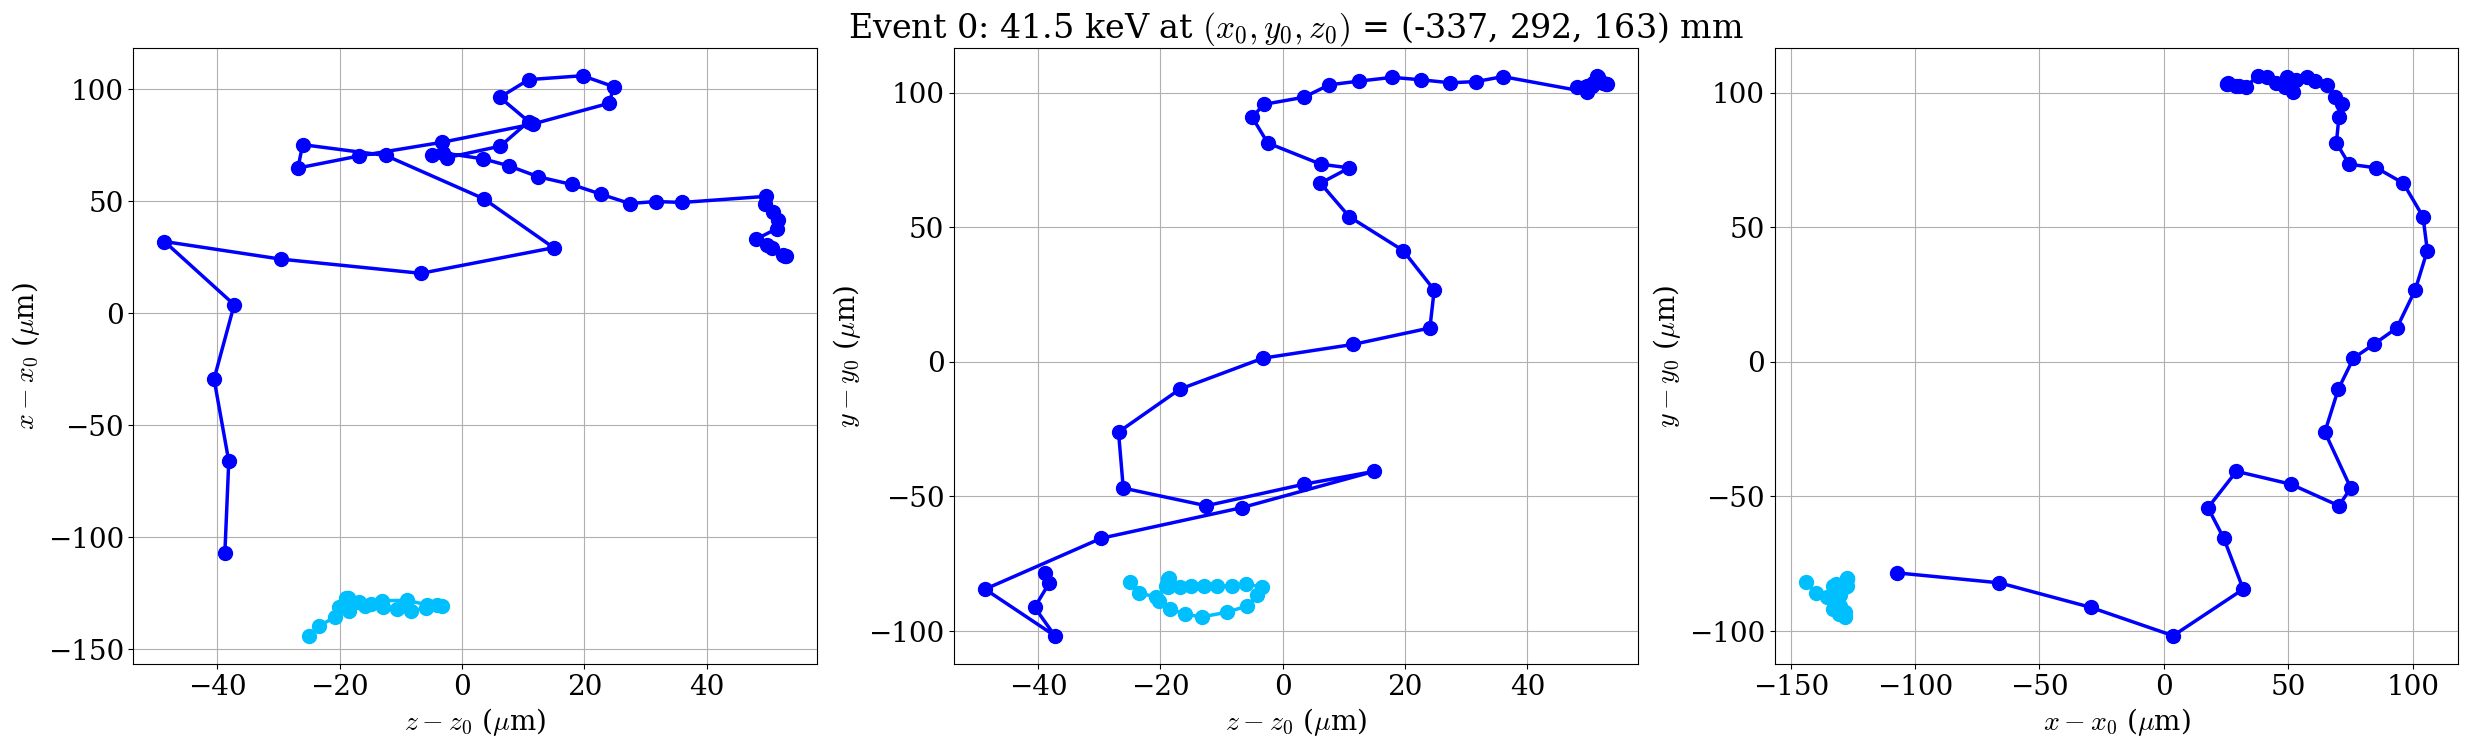

In [10]:
# 1. Hits of one event (fibers file; the PMTs file has the same hits)
show(plots.hits_projections(f_fib, EVENTS[0]), f"hits_{EVENTS[0]}")

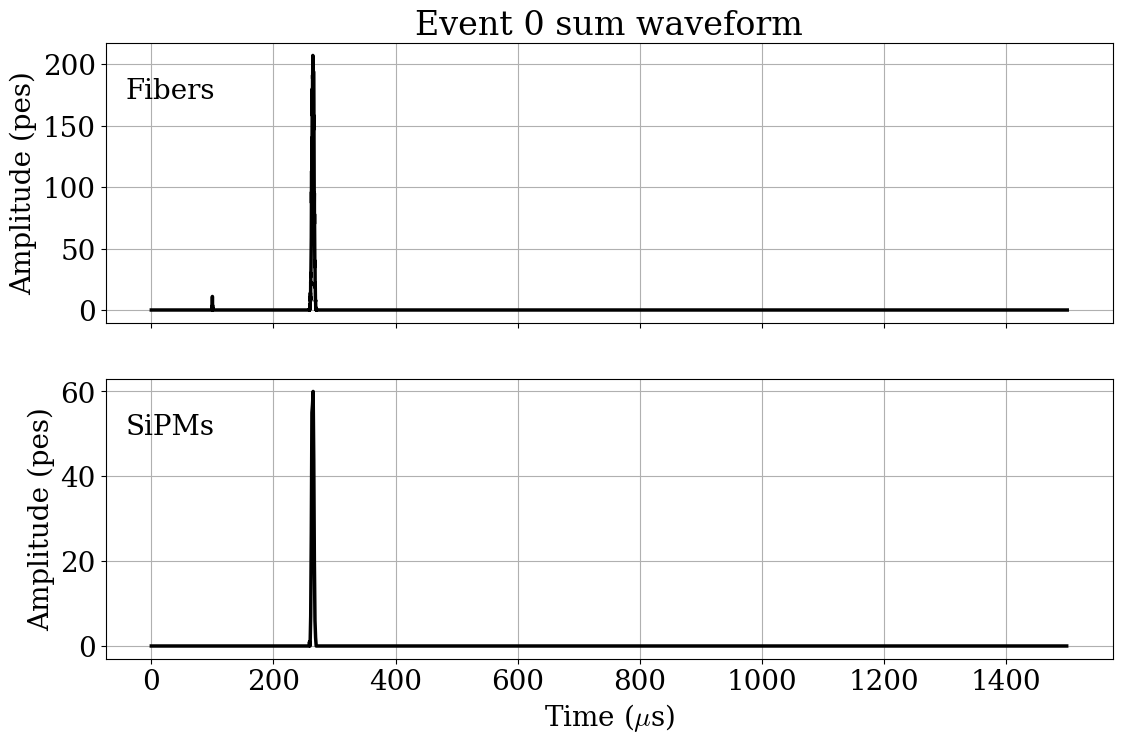

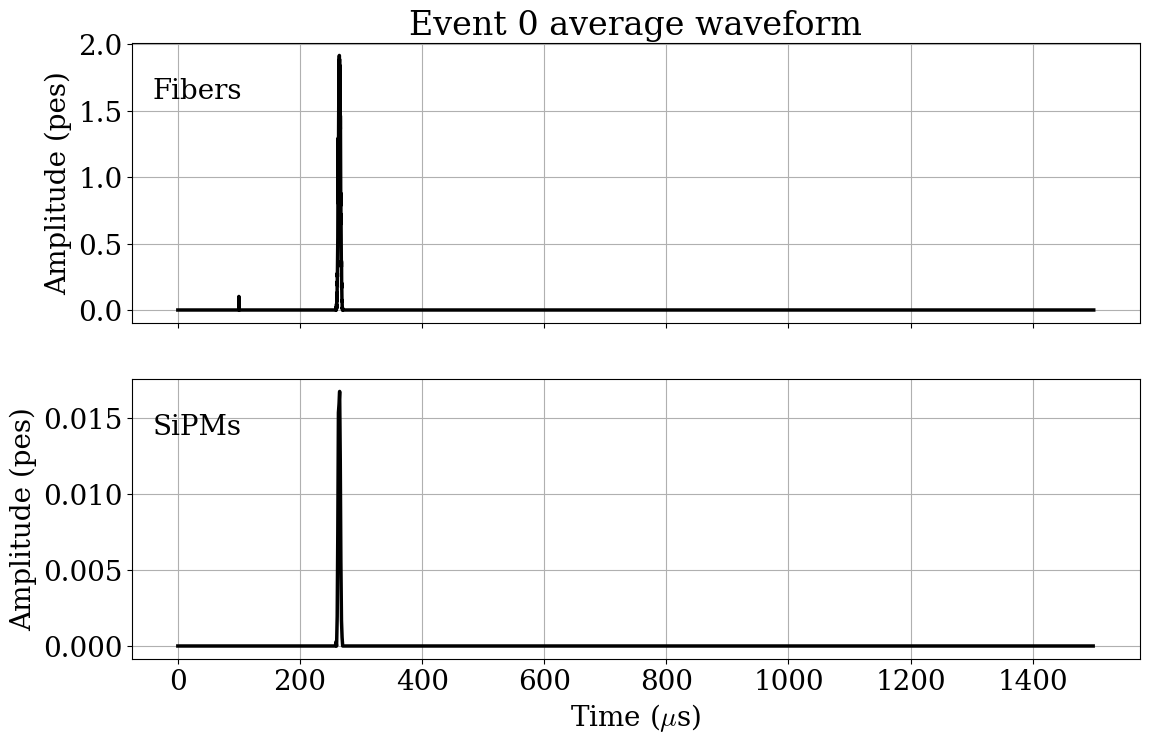

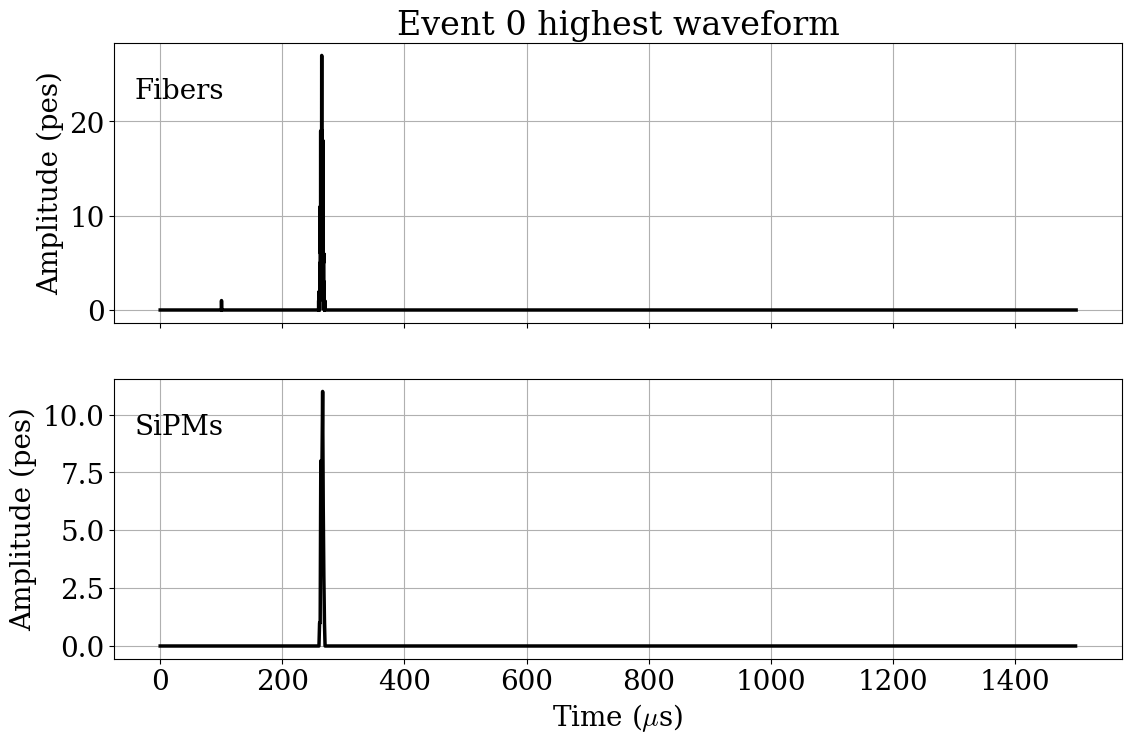

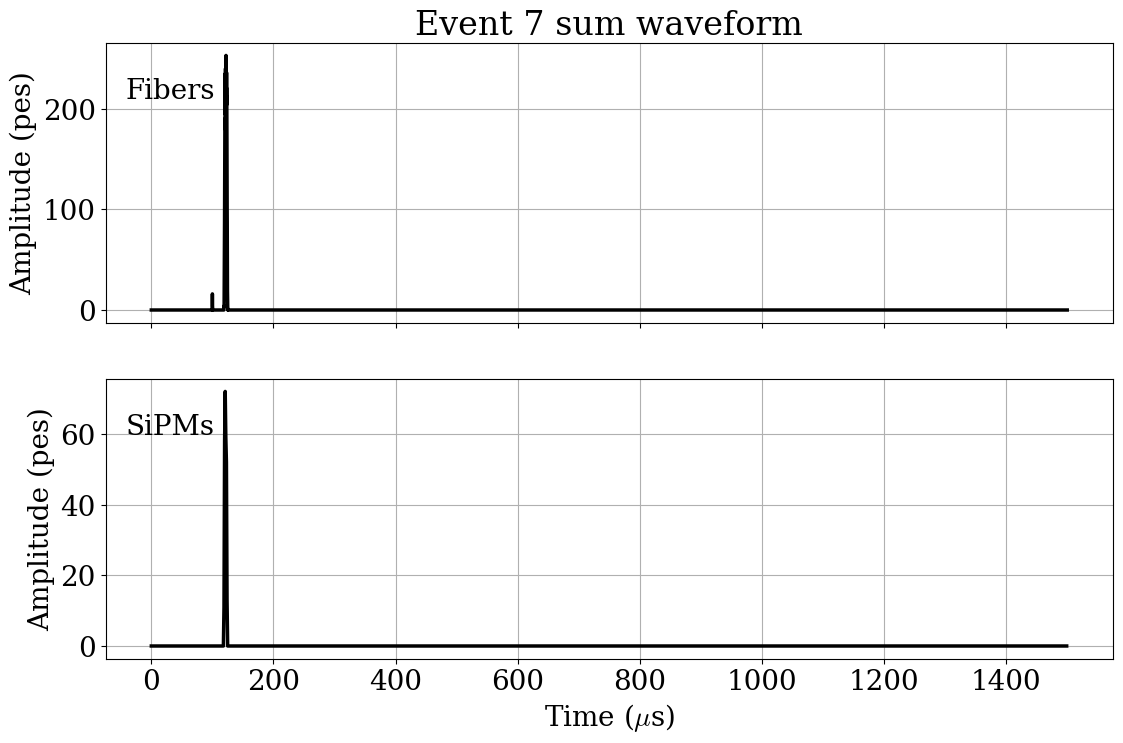

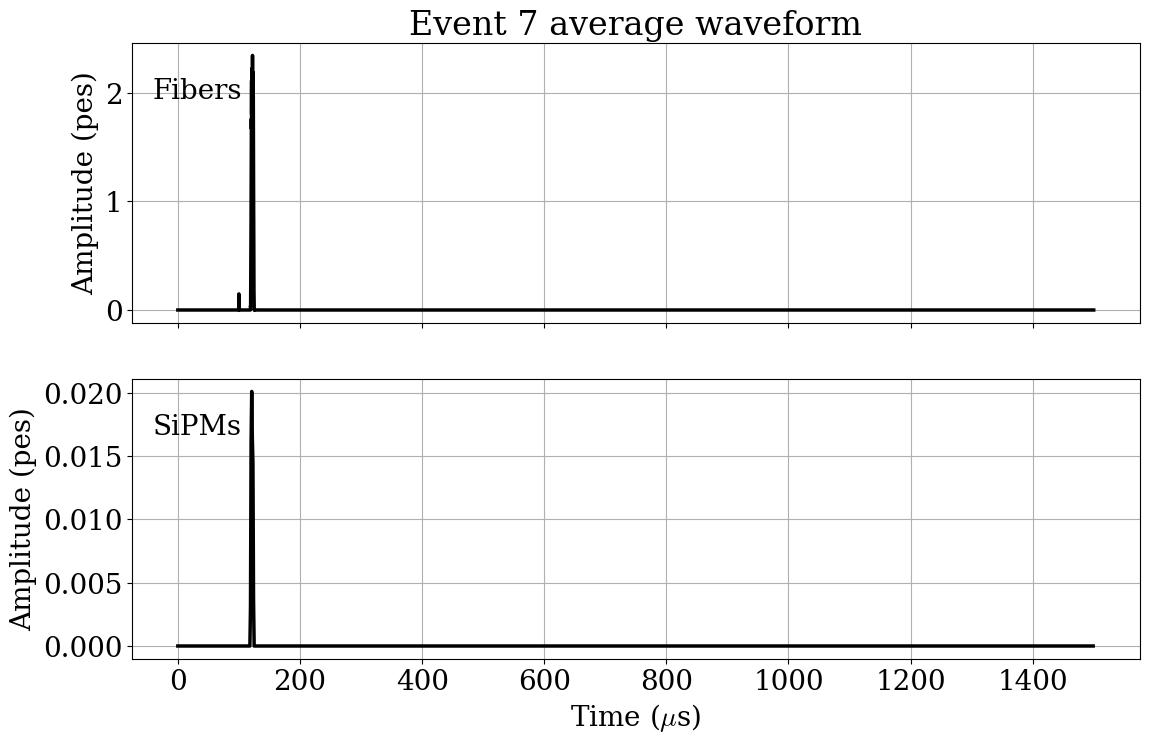

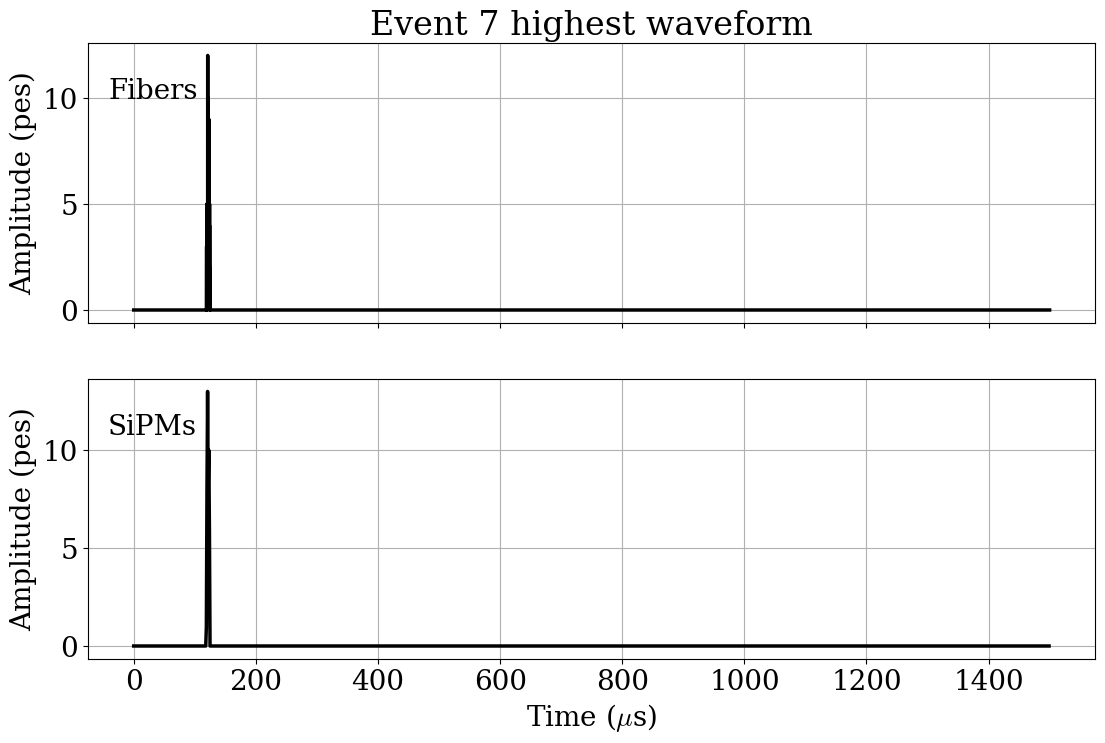

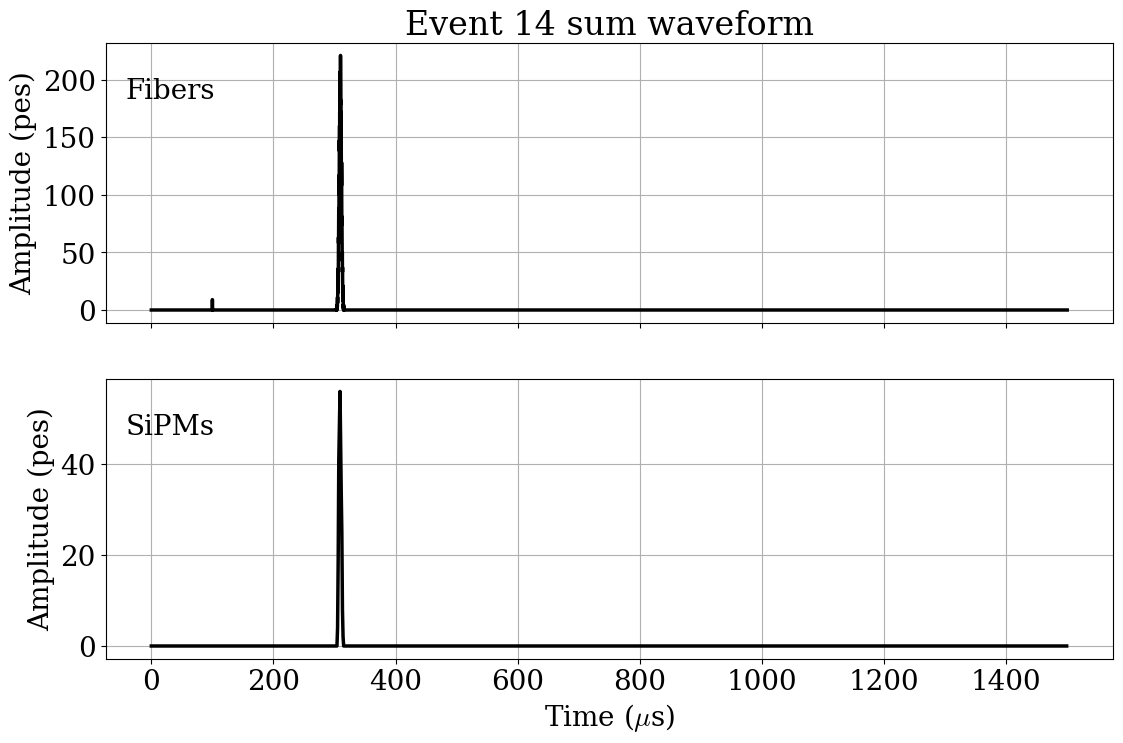

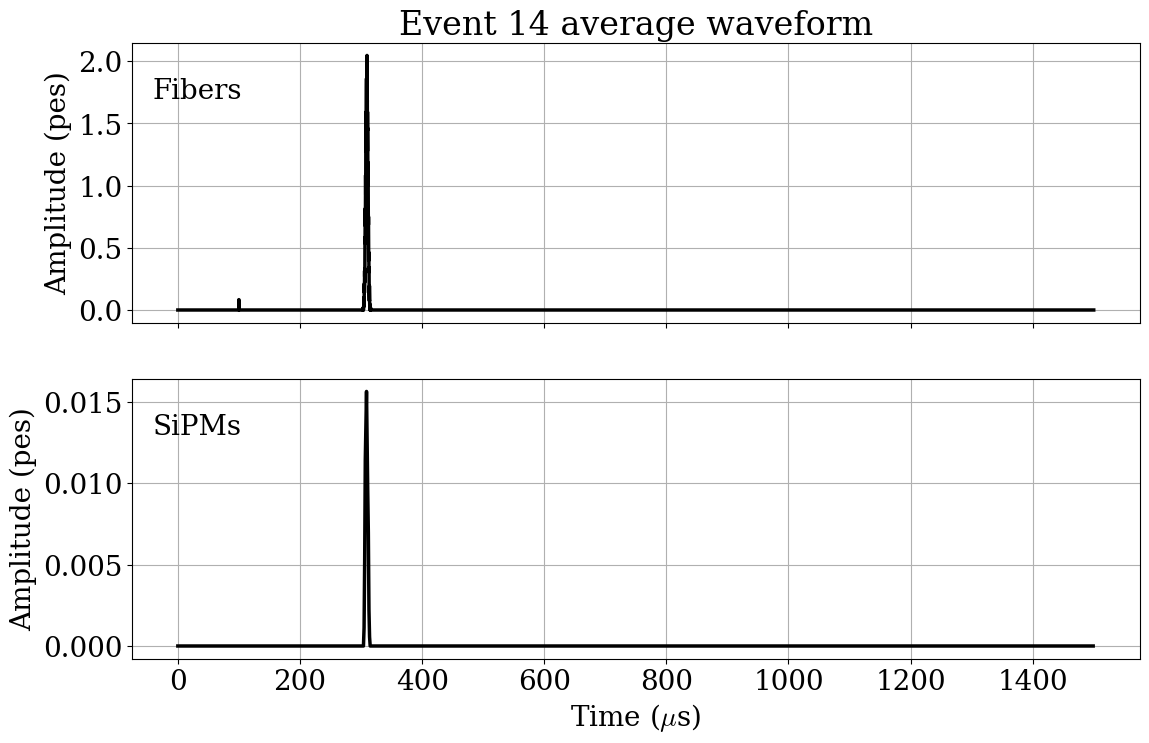

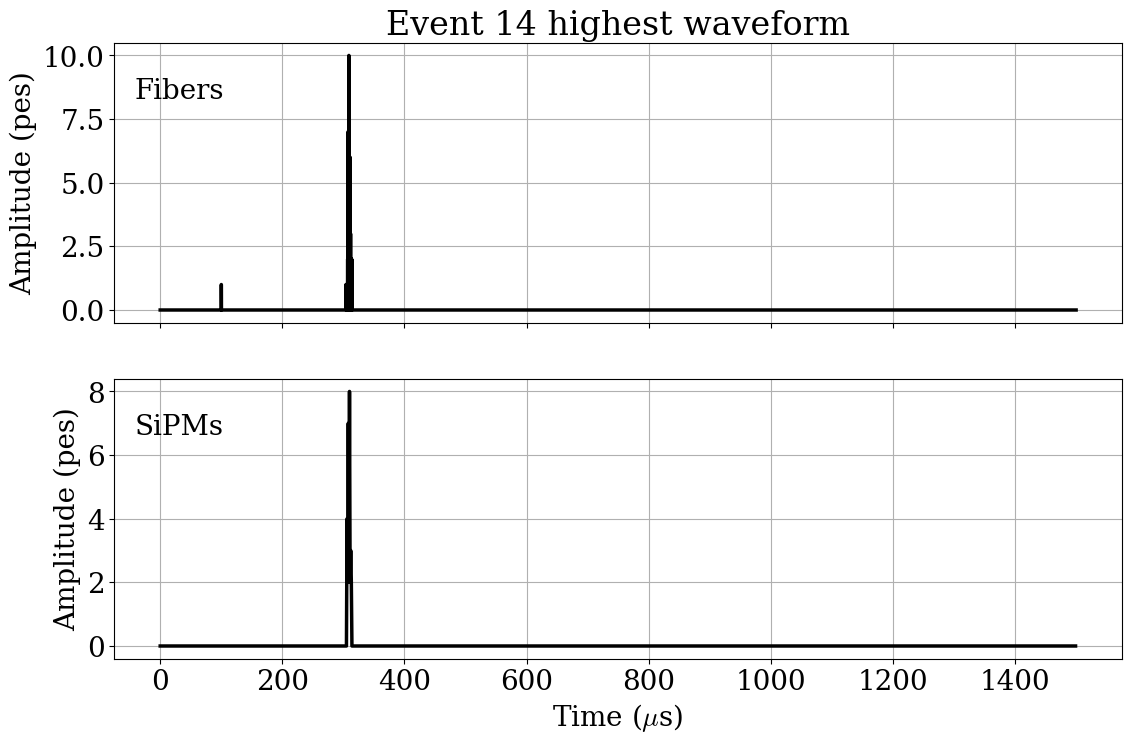

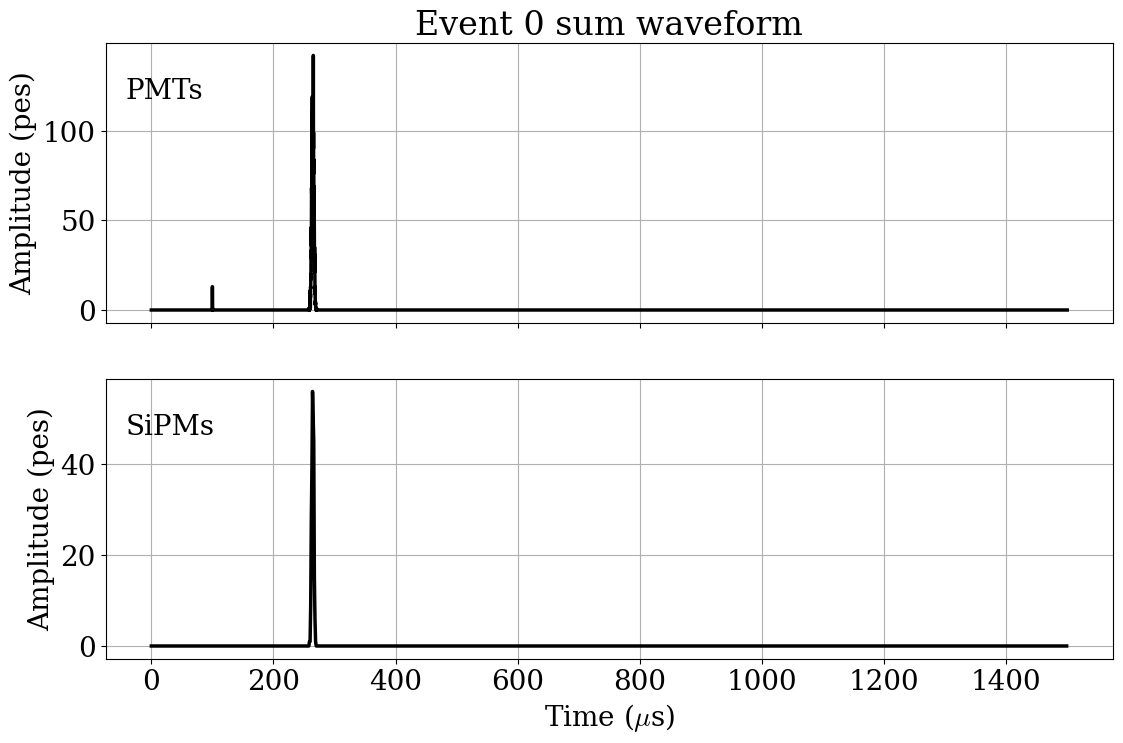

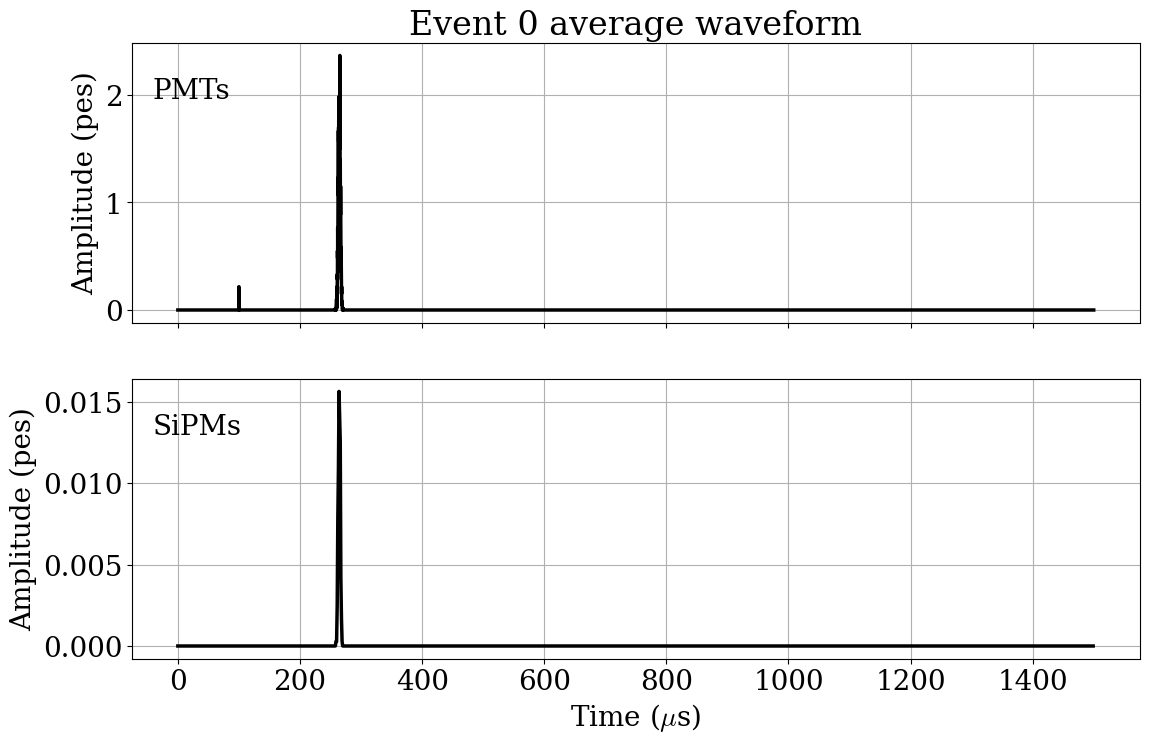

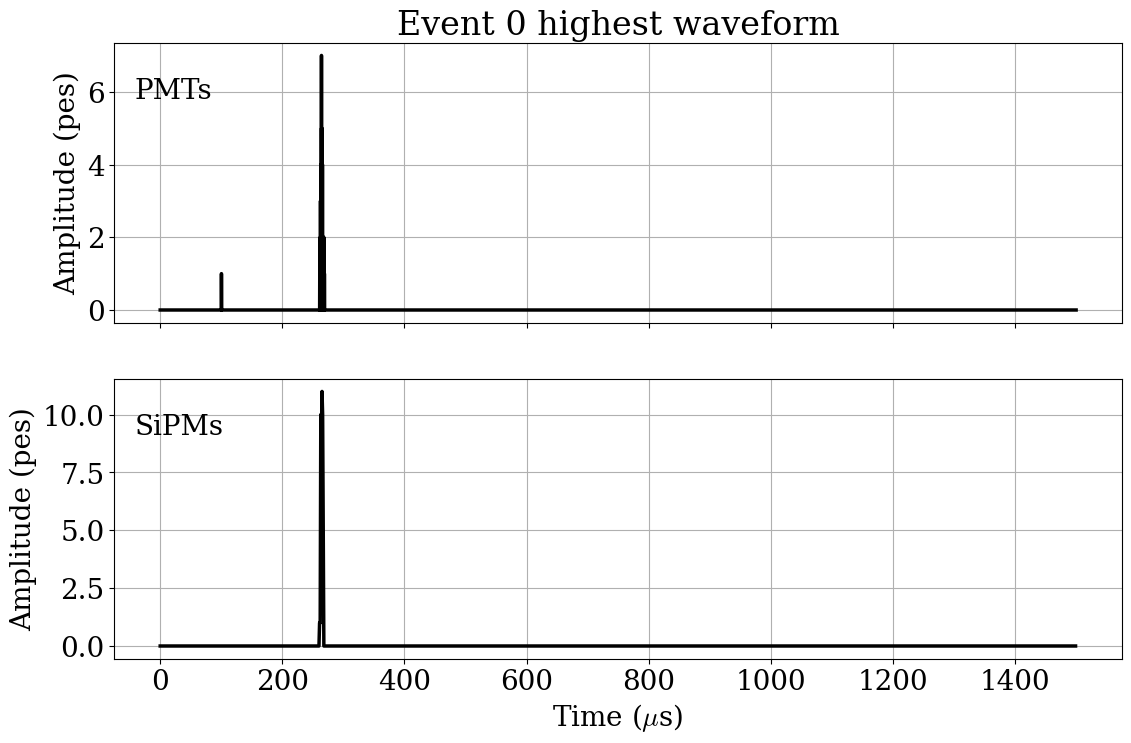

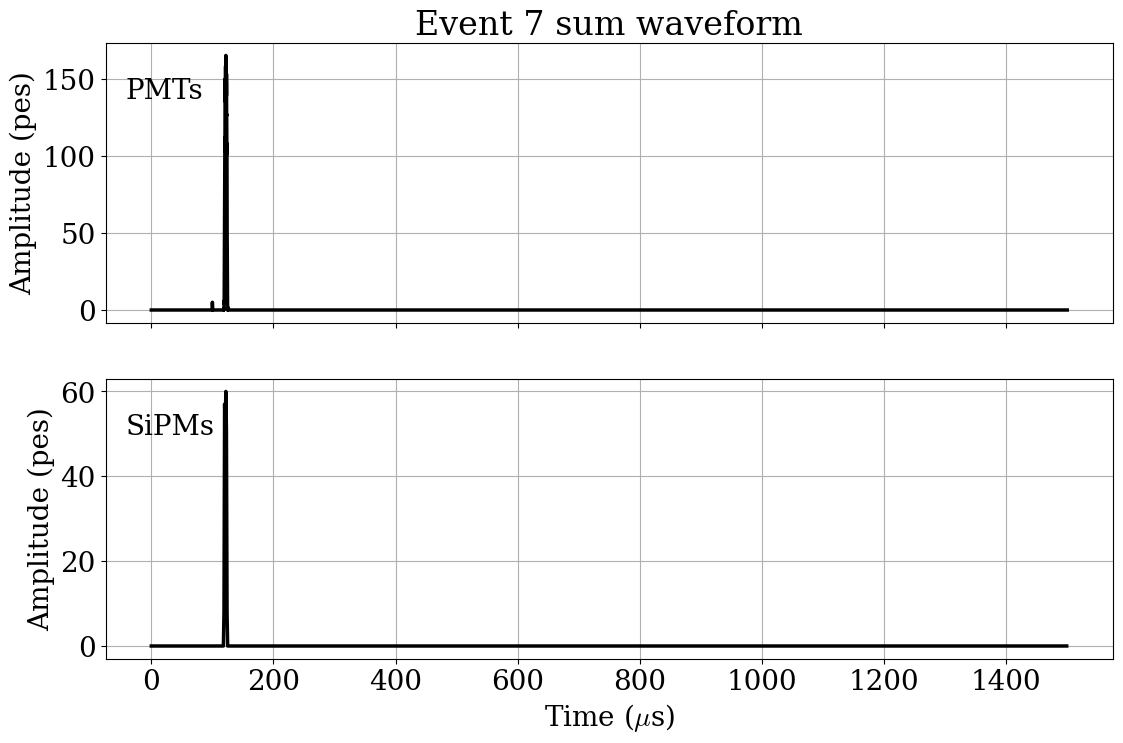

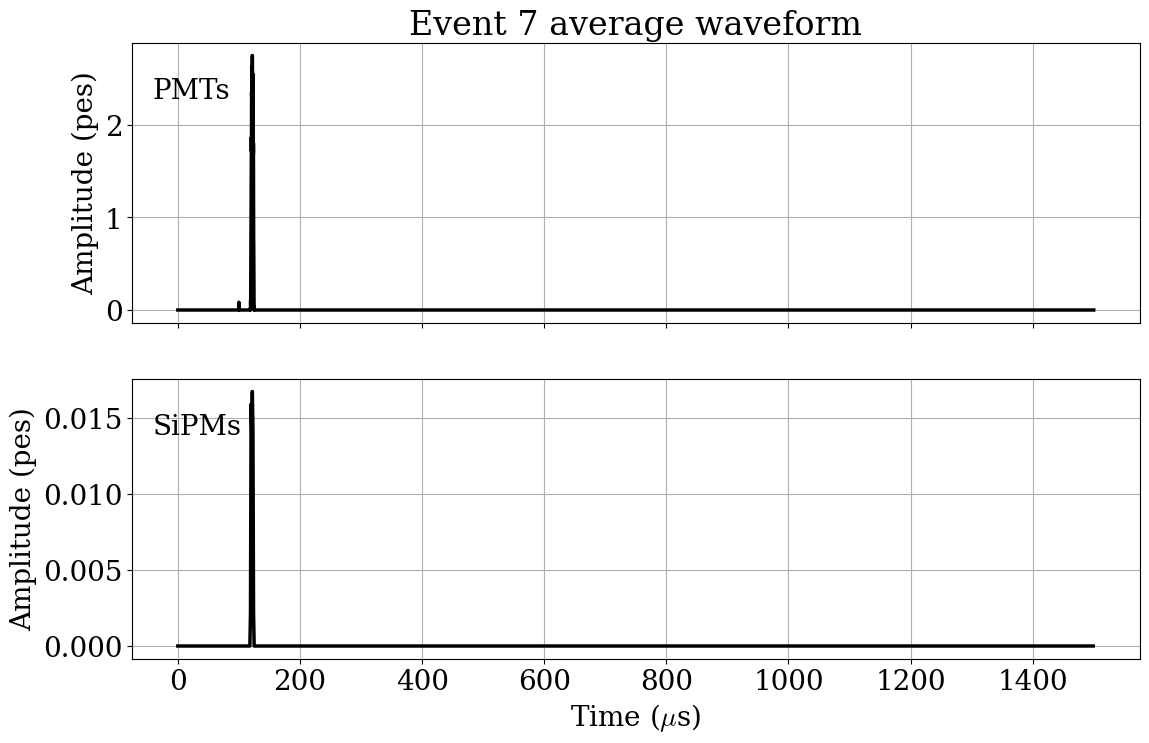

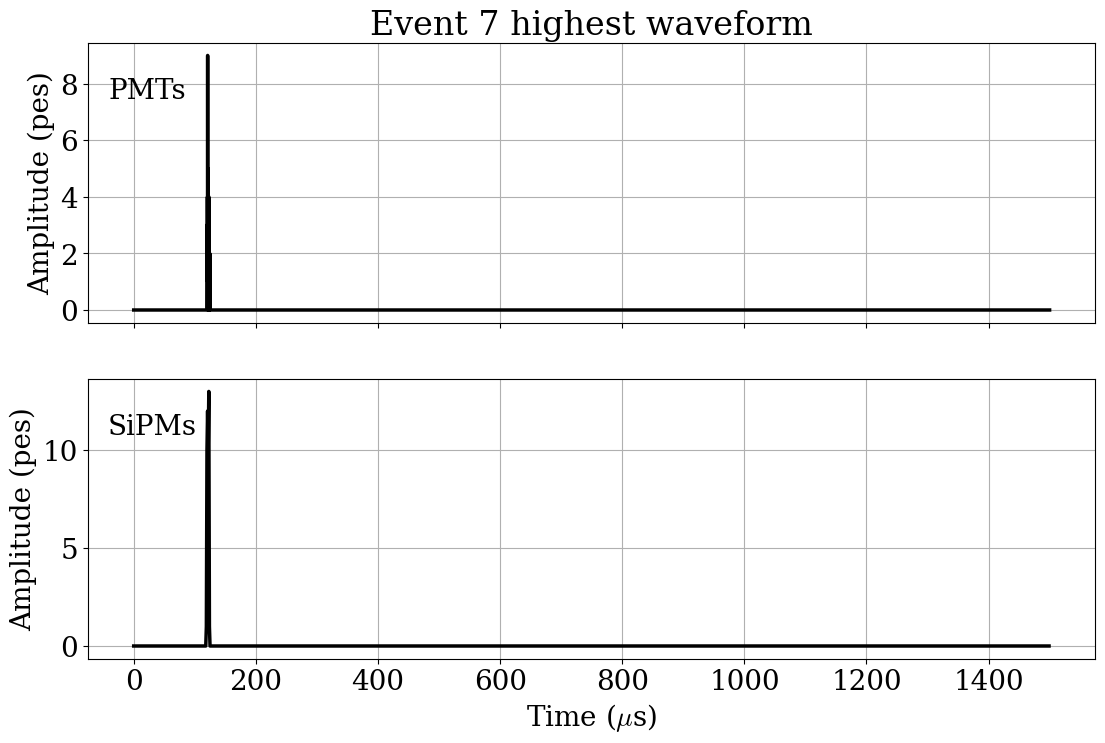

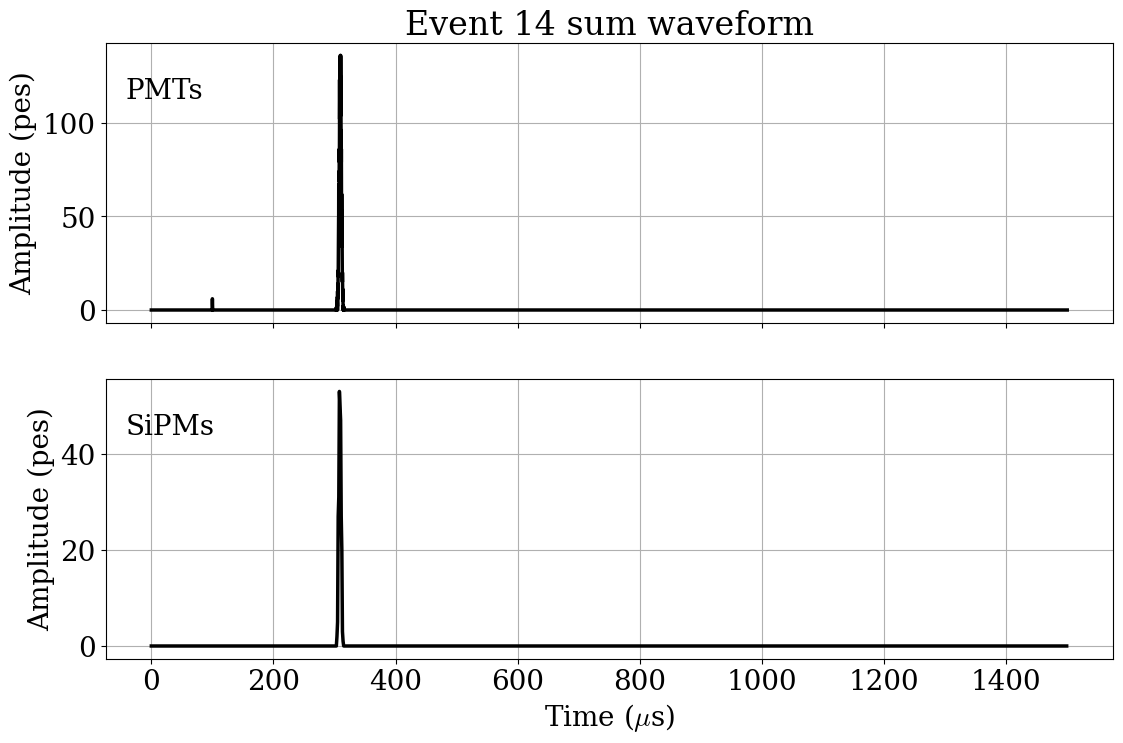

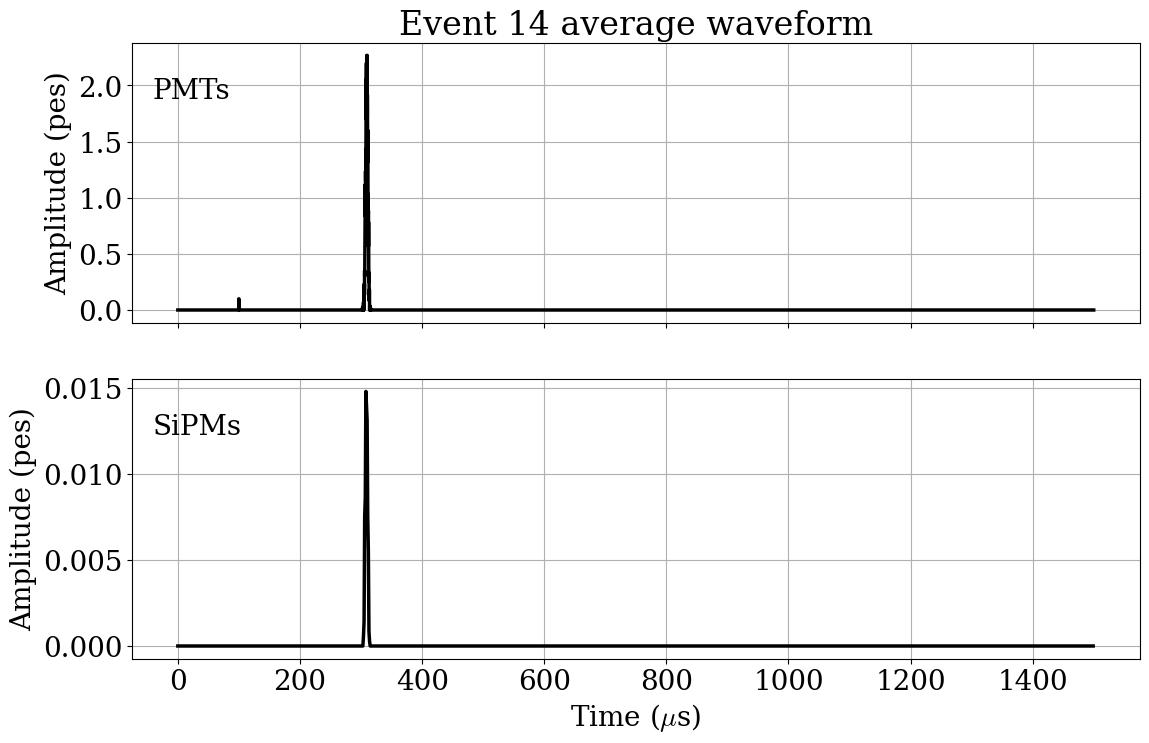

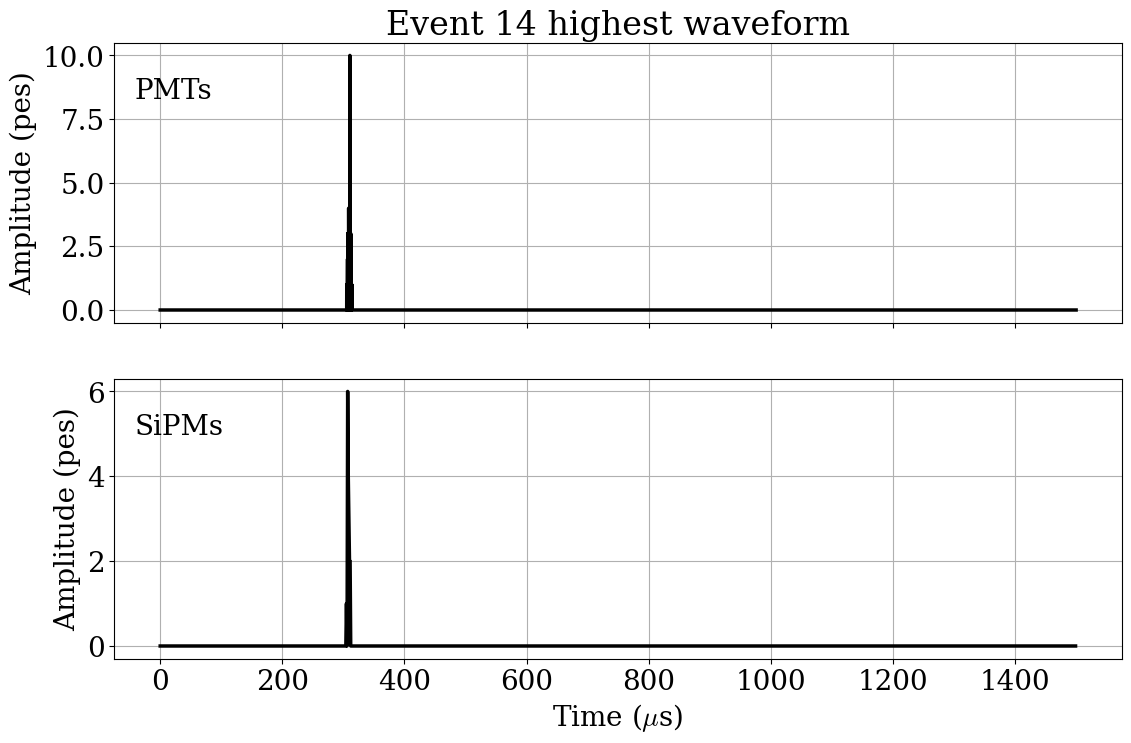

In [11]:
# 2. Waveforms: sum, average and highest channel, fibers and PMTs
for f, det in [(f_fib, "fibers"), (f_pmt, "pmts")]:
    for i in EVENTS:
        for how in ["sum", "average", "highest"]:
            show(plots.waveforms(f, i, how), f"{det}_wf_{how}_{i}")

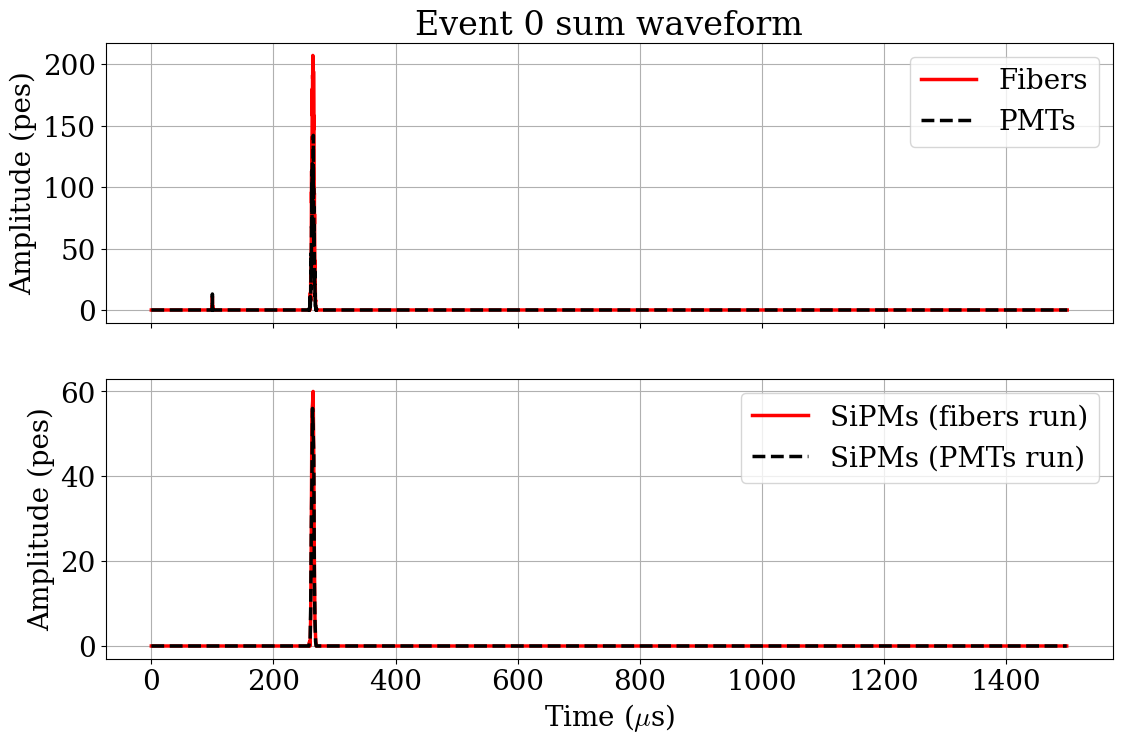

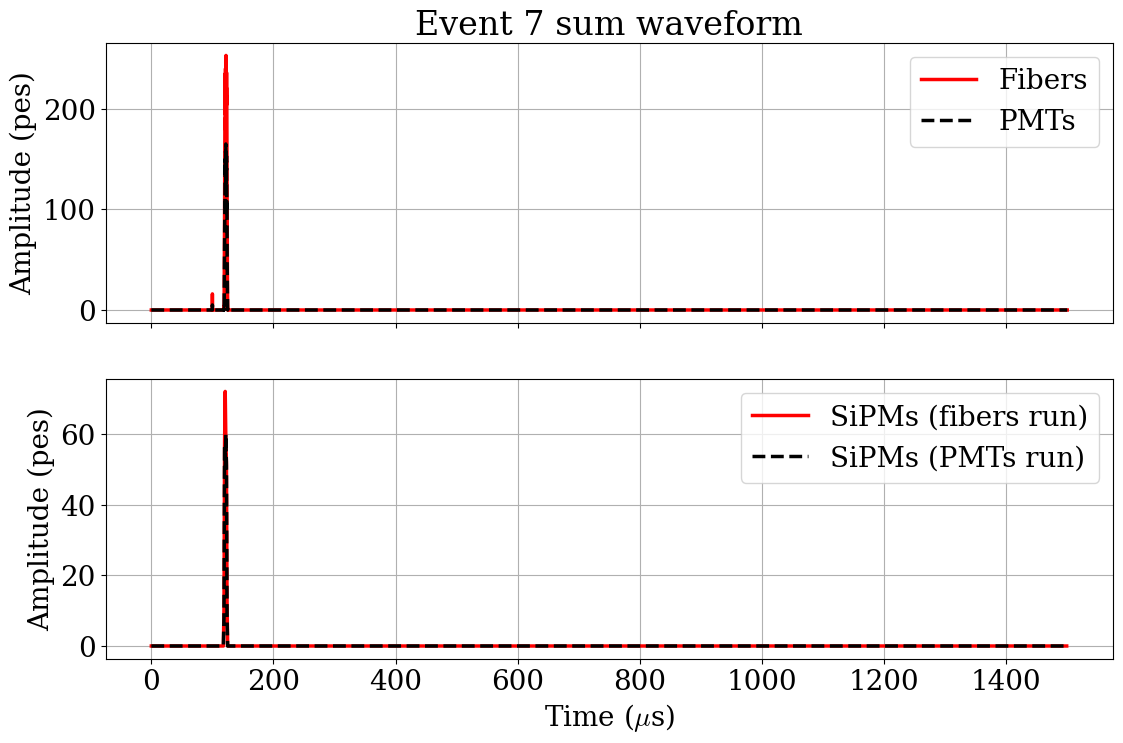

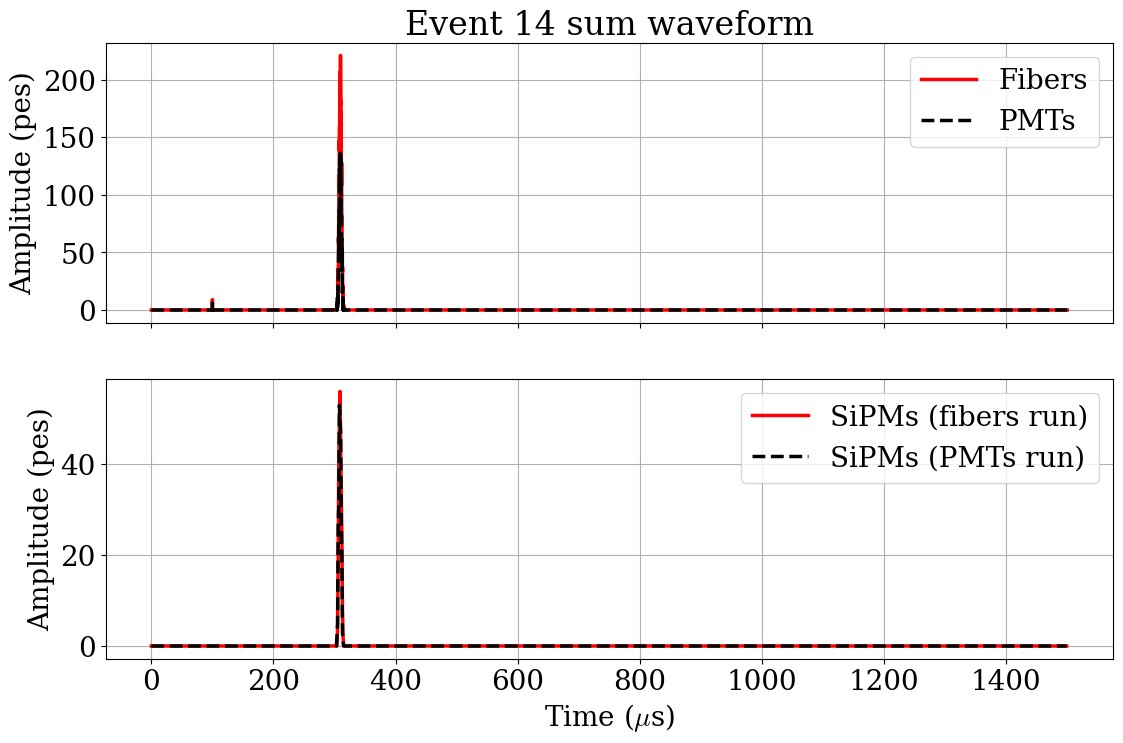

In [12]:
# 3. Fibers vs PMTs, same event
for i in EVENTS:
    show(plots.fib_vs_pmt(f_fib, f_pmt, i), f"fib_vs_pmt_{i}")

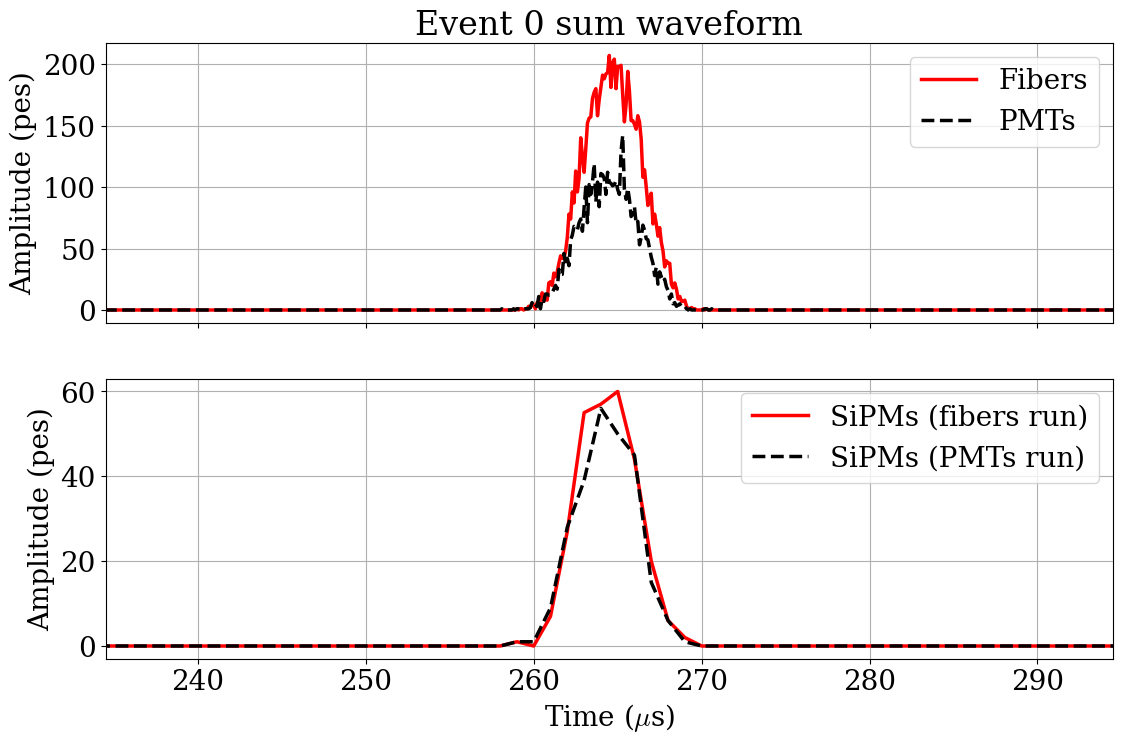

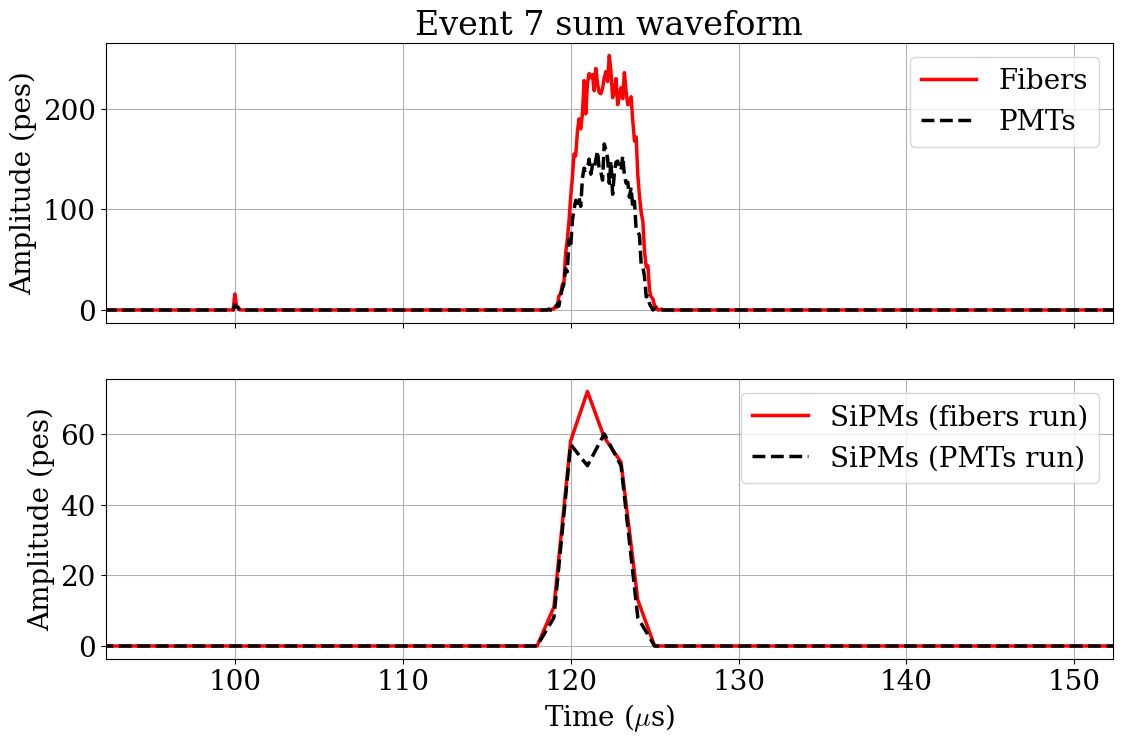

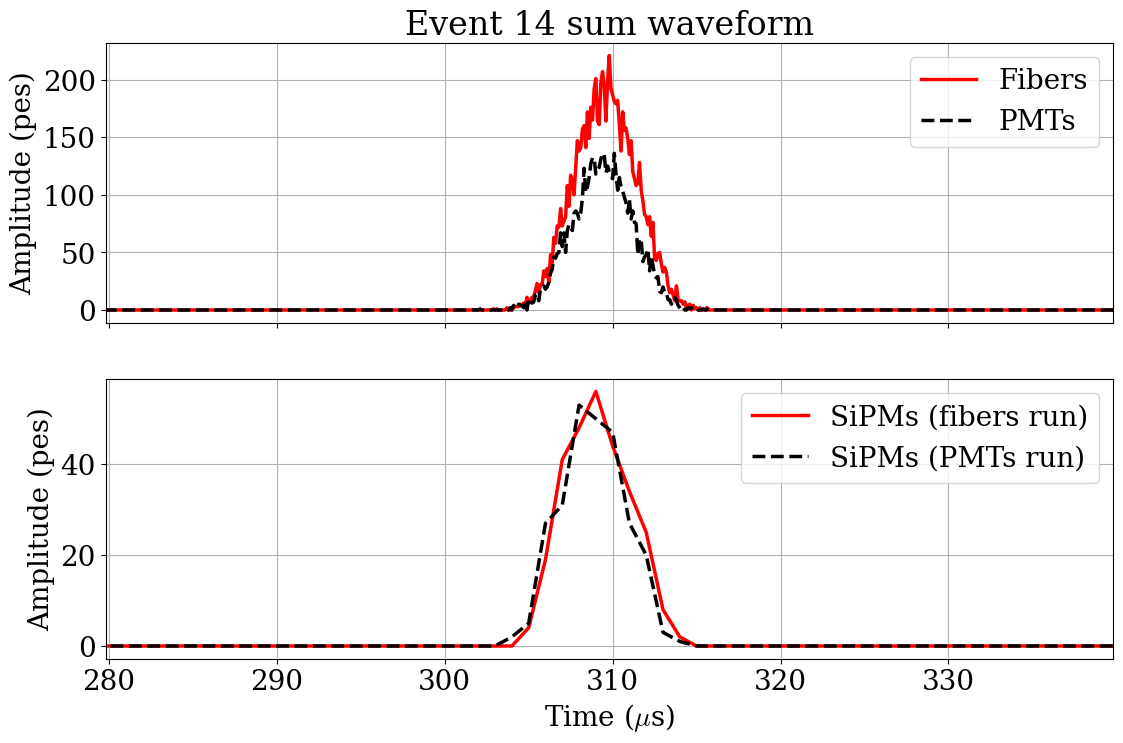

In [13]:
# 4. Zoom on S2: +-30 us around the S2 peak of the fibers sum waveform
import tables as tb
for i in EVENTS:
    with tb.open_file(f_fib) as h:
        t_peak = np.argmax(h.root.fibrd[i].sum(axis=0)[1100:]) * plots.EP_WIDTH_US + 110   # skip S1 (at 100 us)
    show(plots.fib_vs_pmt(f_fib, f_pmt, i, xlim=(t_peak - 30, t_peak + 30)), f"fib_vs_pmt_S2zoom_{i}")

In [14]:
import tables as tb
def integrals(path, node, n_events=200, s1=(990, 1015)):
    # EP waveforms: 100 ns bins, S1 at 100 us (bin 1000); S2 after it
    with tb.open_file(path) as h:
        wf = getattr(h.root, node)
        out = []
        for e in range(min(n_events, wf.shape[0])):
            w = wf[e].astype(float).sum(axis=0)
            out.append((w[s1[0]:s1[1]].sum(), w[s1[1]:].sum()))
    return np.array(out)
fib = integrals(f_fib, "fibrd"); pmt = integrals(f_pmt, "pmtrd")
print(f"median S1: fibers {np.median(fib[:,0]):.1f}, PMTs {np.median(pmt[:,0]):.1f} adc, ratio {np.median(fib[:,0])/np.median(pmt[:,0]):.2f}")
print(f"median S2: fibers {np.median(fib[:,1]):.0f}, PMTs {np.median(pmt[:,1]):.0f} adc, ratio {np.median(fib[:,1])/np.median(pmt[:,1]):.2f}")

median S1: fibers 29.0, PMTs 15.0 adc, ratio 1.93
median S2: fibers 8766, PMTs 5240 adc, ratio 1.67


### The fiber S1 is a placeholder
`detsim.py:scale_and_repeat_s1` builds the 108 fiber S1 waveforms from the 60 PMT S1 waveforms: `scaling_factor = 1` (the 60/108 line is commented out), all 60 copied, then the first 48 again.
So fiber S1 / PMT S1 ≈ 1 + (light in PMTs 0-47)/(all PMT light), about 1.8, by construction. The S2 ratio comes from the fiber S2 table and is physics.
Check below: fiber channels 60-107 must be identical to channels 0-47 in the S1 window.

In [15]:
with tb.open_file(f_fib) as h:
    w = h.root.fibrd[0].astype(float)
s1 = w[:, 990:1015]
print("channels 60-107 equal to 0-47 in the S1 window:", np.allclose(s1[60:108], s1[0:48]))

channels 60-107 equal to 0-47 in the S1 window: True
